In [ ]:

import requests
import pandas as pd
import sqlite3
import time
import json

print("Legal API Engineering Lab initialized!")
print("Python libraries loaded successfully.")


Legal API Engineering Lab initialized!
Python libraries loaded successfully.


In [ ]:

# STEP 2: Test an API connection

url = "https://httpbin.org/get"

try:
    start_time = time.perf_counter()

    response = requests.get(url, timeout=10)

    elapsed = time.perf_counter() - start_time

    print("HTTP Status Code:", response.status_code)
    print("Response Time:", round(elapsed, 3), "seconds")

    response.raise_for_status()

    data = response.json()

    print("\nAPI Response:")
    print(json.dumps(data, indent=4))

except requests.exceptions.RequestException as error:
    print("API Request Failed:", error)



HTTP Status Code: 200
Response Time: 0.182 seconds

API Response:
{
    "args": {},
    "headers": {
        "Accept": "*/*",
        "Accept-Encoding": "gzip, deflate, br, zstd",
        "Host": "httpbin.org",
        "User-Agent": "python-requests/2.32.4",
        "X-Amzn-Trace-Id": "Root=1-6adf7527-10ff18106c2b1e2330c2b2c6"
    },
    "origin": "136.80.60.9",
    "url": "https://httpbin.org/get"
}


In [ ]:

# STEP 3: Automated API validation

def test_api_response(response, data):

    print("Running API Validation Tests...\n")

    assert response.status_code == 200, "HTTP status test failed"
    print("PASS: HTTP status is 200")

    assert isinstance(data, dict), "JSON structure test failed"
    print("PASS: JSON is a Python dictionary")

    assert "headers" in data, "Missing headers"
    print("PASS: Response contains headers")

    assert "url" in data, "Missing URL"
    print("PASS: Response contains URL")

    assert data["url"] == "https://httpbin.org/get", "Unexpected URL"
    print("PASS: API returned the expected URL")

    print("\nAll 5 API validation tests passed!")

test_api_response(response, data)


Running API Validation Tests...

PASS: HTTP status is 200
PASS: JSON is a Python dictionary
PASS: Response contains headers
PASS: Response contains URL
PASS: API returned the expected URL

All 5 API validation tests passed!


In [ ]:

# STEP 4: Test CourtListener API connection

legal_api_url = "https://www.courtlistener.com/api/rest/v3/search/"

print("Connecting to CourtListener Legal API...\n")

try:
    start_time = time.perf_counter()

    legal_response = requests.get(
        legal_api_url,
        params={"q": "Fourth Amendment", "type": "o"},
        timeout=15
    )

    elapsed = time.perf_counter() - start_time

    print("HTTP Status:", legal_response.status_code)
    print("Response Time:", round(elapsed, 3), "seconds")
    print("Content Type:", legal_response.headers.get("Content-Type"))

    if legal_response.status_code == 200:
        legal_data = legal_response.json()
        print("\nSUCCESS: Legal API connection established!")
        print("Response fields:", list(legal_data.keys()))

    elif legal_response.status_code in (401, 403):
        print("\nAuthentication or access permission required.")
        print("We'll configure API access next.")

    else:
        print("\nAPI returned:", legal_response.status_code)
        print(legal_response.text[:300])

except requests.exceptions.RequestException as error:
    print("Connection error:", error)


Connecting to CourtListener Legal API...

HTTP Status: 403
Response Time: 1.91 seconds
Content Type: application/json

Authentication or access permission required.
We'll configure API access next.


In [ ]:

# STEP 5: Connect to CourtListener API v4

legal_api_url = "https://www.courtlistener.com/api/rest/v4/search/"

params = {
    "q": "Fourth Amendment",
    "type": "o"
}

try:
    response = requests.get(
        legal_api_url,
        params=params,
        timeout=20
    )

    print("HTTP Status:", response.status_code)

    if response.status_code == 200:
        legal_data = response.json()

        print("SUCCESS: Connected to CourtListener!")
        print("Total matching cases:", legal_data.get("count"))
        print("Cases on this page:", len(legal_data.get("results", [])))

    else:
        print("API Response:", response.text[:500])

except requests.exceptions.RequestException as error:
    print("Connection Error:", error)


HTTP Status: 200
SUCCESS: Connected to CourtListener!
Total matching cases: 642259
Cases on this page: 20


In [ ]:

# STEP 6: Convert legal API results into a DataFrame

cases = legal_data.get("results", [])

case_records = []

for case in cases:
    case_records.append({
        "Case Name": case.get("caseName"),
        "Court": case.get("court"),
        "Date Filed": case.get("dateFiled"),
        "Citation": case.get("citation"),
        "Case ID": case.get("cluster_id")
    })

df = pd.DataFrame(case_records)

print("Legal DataFrame Created!")
print("Total records:", len(df))
print("Columns:", list(df.columns))

display(df.head(10))


Legal DataFrame Created!
Total records: 20
Columns: ['Case Name', 'Court', 'Date Filed', 'Citation', 'Case ID']


,Case Name,Court,Date Filed,Citation,Case ID
0,In re Terrorist Bombings of U.S. Embassies (Fo...,Court of Appeals for the Second Circuit,2008-11-24,[],2550
1,In Re Amendment to Administrative Plan for the...,Supreme Court of Arkansas,2025-04-24,[2025 Ark. 51],10611344
2,Fourth Amendment Issues Raised by Chemical Wea...,Department of Justice Office of Legal Counsel,1996-09-10,[],4342405
3,Environmental Protection Agency Overflights an...,Department of Justice Office of Legal Counsel,1980-09-23,[],4342924
4,Fourth Amendment Implications of Military Use ...,Department of Justice Office of Legal Counsel,1992-03-04,[],4342527
5,Ratification of the Equal Rights Amendment,Department of Justice Office of Legal Counsel,2020-01-06,[],4713839
6,Ratification of the Equal Rights Amendment,Department of Justice Office of Legal Counsel,2020-01-06,[],4692949
7,Knight First Amendment Institute at Columbia U...,Court of Appeals for the D.C. Circuit,2021-08-27,[11 F.4th 810],5064123
8,Application of Fourth Amendment to Use of Elec...,Department of Justice Office of Legal Counsel,1986-12-05,[],4342671
9,"Cincinnati v. Fourth Natl. Realty, L.L.C.",Ohio Court of Appeals,2023-03-29,"[214 N.E.3d 1, 2023 Ohio 1012]",9387517


In [ ]:

# STEP 7: Legal Data Quality Analyzer

print("LEGAL DATA QUALITY REPORT")
print("=" * 45)

# Check missing values
print("\n1. Missing Values:")
print(df.isnull().sum())

# Check empty citation lists
missing_citations = df["Citation"].apply(
    lambda x: (
        x is None
        or (isinstance(x, list) and len(x) == 0)
        or (isinstance(x, str) and not x.strip())
    )
)

print("\n2. Citation Quality:")
print("Records with empty citations:", missing_citations.sum())

# Check duplicate case IDs
duplicates = df["Case ID"].duplicated().sum()

print("\n3. Duplicate Case IDs:")
print("Duplicates found:", duplicates)

# Calculate completeness
required_columns = ["Case Name", "Court", "Date Filed", "Case ID"]

complete_rows = df[required_columns].notna().all(axis=1)

completeness = complete_rows.mean() * 100

print("\n4. Required Field Completeness:")
print(f"{completeness:.2f}%")

print("\n5. Dataset Summary:")
print("Total cases analyzed:", len(df))
print("Total columns:", len(df.columns))

print("\nData quality analysis complete!")


LEGAL DATA QUALITY REPORT

1. Missing Values:
Case Name     0
Court         0
Date Filed    0
Citation      0
Case ID       0
dtype: int64

2. Citation Quality:
Records with empty citations: 11

3. Duplicate Case IDs:
Duplicates found: 0

4. Required Field Completeness:
100.00%

5. Dataset Summary:
Total cases analyzed: 20
Total columns: 5

Data quality analysis complete!


In [ ]:

# STEP 8: Legal Data SQL Analysis

# Create an in-memory SQLite database
conn = sqlite3.connect(":memory:")

# Prepare citations for SQL storage
sql_df = df.copy()

sql_df["Citation"] = sql_df["Citation"].apply(
    lambda x: json.dumps(x) if isinstance(x, list) else x
)

# Store our legal records in SQL
sql_df.to_sql(
    "legal_cases",
    conn,
    if_exists="replace",
    index=False
)

print("SUCCESS: Legal records stored in SQLite!\n")

# SQL Query 1: Count all records
query1 = """
SELECT COUNT(*) AS total_cases
FROM legal_cases;
"""

print("QUERY 1: Total Cases")
display(pd.read_sql_query(query1, conn))

# SQL Query 2: Cases grouped by court
query2 = """
SELECT
    Court,
    COUNT(*) AS case_count
FROM legal_cases
GROUP BY Court
ORDER BY case_count DESC;
"""

print("\nQUERY 2: Cases by Court")
display(pd.read_sql_query(query2, conn))

# SQL Query 3: Most recent cases
query3 = """
SELECT
    "Case Name",
    Court,
    "Date Filed"
FROM legal_cases
ORDER BY "Date Filed" DESC
LIMIT 5;
"""

print("\nQUERY 3: Five Most Recent Cases")
display(pd.read_sql_query(query3, conn))


SUCCESS: Legal records stored in SQLite!

QUERY 1: Total Cases


,total_cases
0,20



QUERY 2: Cases by Court


,Court,case_count
0,Ohio Court of Appeals,6
1,Department of Justice Office of Legal Counsel,6
2,Court of Appeals of North Carolina,4
3,Supreme Court of Arkansas,1
4,Ohio Supreme Court,1
5,Court of Appeals for the Second Circuit,1
6,Court of Appeals for the D.C. Circuit,1



QUERY 3: Five Most Recent Cases


,Case Name,Court,Date Filed
0,State v. Pardo,Court of Appeals of North Carolina,2025-10-01
1,State v. Grady,Ohio Court of Appeals,2025-08-04
2,In re: J.B.P.,Court of Appeals of North Carolina,2025-07-02
3,In Re Amendment to Administrative Plan for the...,Supreme Court of Arkansas,2025-04-24
4,State v. Doering,Ohio Court of Appeals,2025-04-10


In [ ]:

# STEP 9: Automated API Failure Testing Lab

from unittest.mock import Mock
import requests

def validate_api_response(response):
    """Validate HTTP status and JSON structure."""

    response.raise_for_status()

    data = response.json()

    if not isinstance(data, dict):
        raise ValueError("Expected JSON object")

    if "results" not in data:
        raise ValueError("Missing results field")

    if not isinstance(data["results"], list):
        raise ValueError("Results must be a list")

    return True


# Test scenarios
scenarios = [
    (200, {"results": []}, "Valid API Response"),
    (401, {"detail": "Unauthorized"}, "Authentication Error"),
    (403, {"detail": "Forbidden"}, "Permission Error"),
    (404, {"detail": "Not Found"}, "Missing Endpoint"),
    (429, {"detail": "Rate Limit"}, "Rate Limit Error"),
    (500, {"detail": "Server Error"}, "Server Failure"),
    (200, {"wrong_field": []}, "Invalid JSON Structure")
]

print("AUTOMATED API FAILURE TESTING LAB")
print("=" * 45)

passed = 0

for status, payload, name in scenarios:

    mock_response = Mock()
    mock_response.status_code = status
    mock_response.json.return_value = payload

    if status >= 400:
        mock_response.raise_for_status.side_effect = (
            requests.exceptions.HTTPError(
                f"HTTP {status}"
            )
        )
    else:
        mock_response.raise_for_status.return_value = None

    try:
        validate_api_response(mock_response)
        actual = "accepted"

    except (requests.exceptions.HTTPError, ValueError):
        actual = "rejected"

    expected = "accepted" if (
        status == 200 and "results" in payload
    ) else "rejected"

    assert actual == expected, f"FAILED: {name}"

    passed += 1
    print(f"PASS: {name} — correctly {actual}")

print("\n" + "=" * 45)
print(f"TEST RESULTS: {passed}/{len(scenarios)} PASSED")


AUTOMATED API FAILURE TESTING LAB
PASS: Valid API Response — correctly accepted
PASS: Authentication Error — correctly rejected
PASS: Permission Error — correctly rejected
PASS: Missing Endpoint — correctly rejected
PASS: Rate Limit Error — correctly rejected
PASS: Server Failure — correctly rejected
PASS: Invalid JSON Structure — correctly rejected

TEST RESULTS: 7/7 PASSED


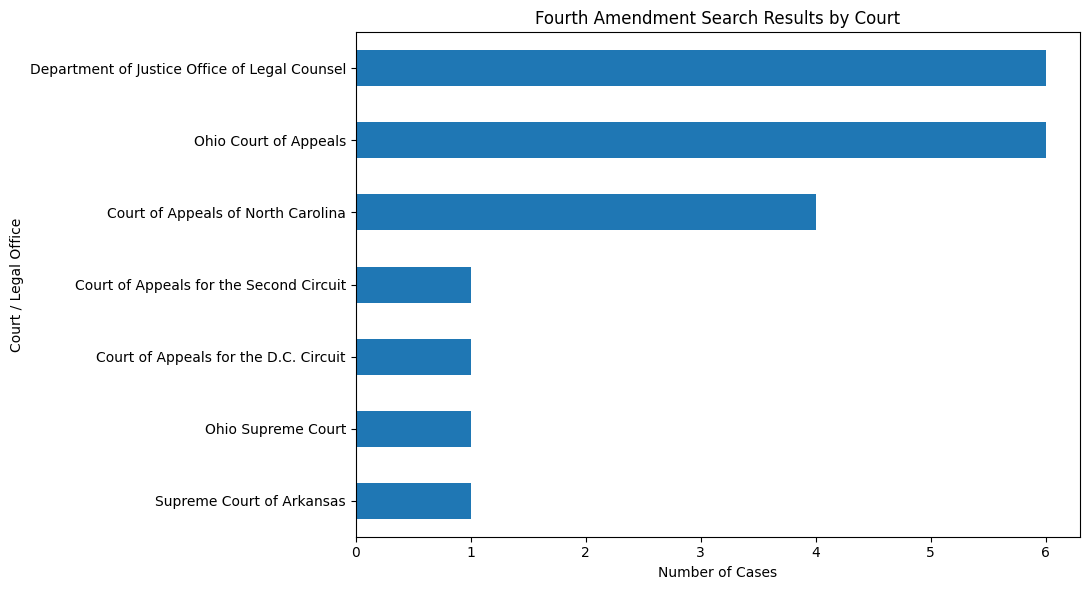

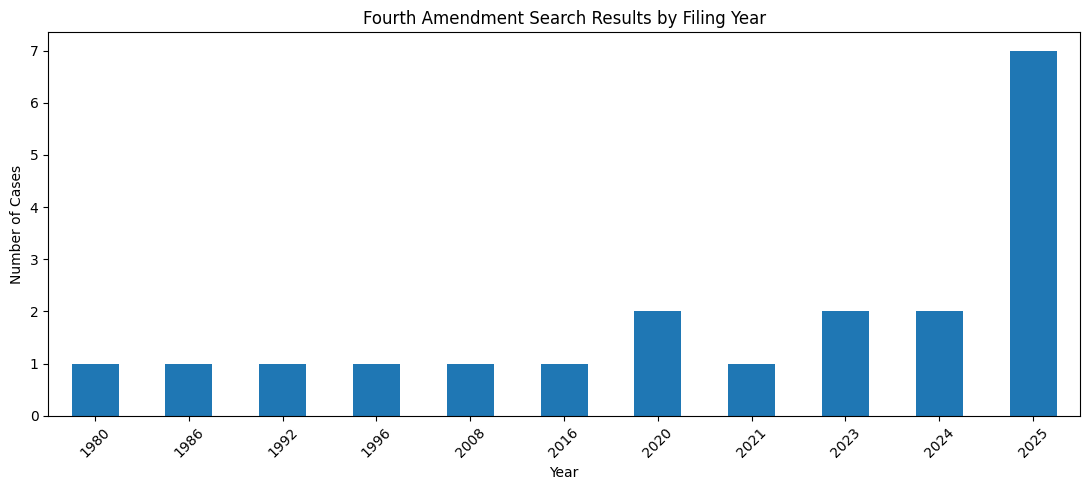

SUCCESS: Legal data visualizations generated!


In [ ]:

# STEP 10: Legal Data Visualization

import matplotlib.pyplot as plt

# Chart 1: Cases by Court
court_counts = df["Court"].value_counts()

plt.figure(figsize=(11, 6))

court_counts.sort_values().plot(
    kind="barh"
)

plt.title("Fourth Amendment Search Results by Court")
plt.xlabel("Number of Cases")
plt.ylabel("Court / Legal Office")
plt.tight_layout()
plt.show()


# Chart 2: Cases by Filing Year
df["Year"] = pd.to_datetime(
    df["Date Filed"],
    errors="coerce"
).dt.year

year_counts = df["Year"].dropna().value_counts().sort_index()

plt.figure(figsize=(11, 5))

year_counts.plot(
    kind="bar"
)

plt.title("Fourth Amendment Search Results by Filing Year")
plt.xlabel("Year")
plt.ylabel("Number of Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("SUCCESS: Legal data visualizations generated!")


In [ ]:
# Legal API Engineering Lab — Interactive Case Search

import requests

search_term = input("Enter a case name or legal topic: ").strip()

if search_term:
    url = "https://www.courtlistener.com/api/rest/v4/search/"

    response = requests.get(
        url,
        params={"q": search_term, "type": "o"},
        timeout=20
    )

    print("API Status:", response.status_code)

    if response.status_code == 200:
        search_data = response.json()
        print("Matching cases:", search_data.get("count", 0))

        for case in search_data.get("results", [])[:5]:
            print("Case:", case.get("caseName"))
            print("Court:", case.get("court"))
            print("Date:", case.get("dateFiled"))
            print("---")
    else:
        print("The search failed. Please try again.")
else:
    print("Please enter a case name or topic.")

Enter a case name or legal topic: Palsgraf v. Long Island Railroad
API Status: 200
Matching cases: 453
Case: Palsgraf v. Long Island Railroad
Court: Appellate Division of the Supreme Court of the State of New York
Date: 1927-12-09
---
Case: Palsgraf v. Long Island Railroad Company
Court: New York Court of Appeals
Date: 1928-10-09
---
Case: Long v. Fowler
Court: Court of Appeals of North Carolina
Date: 2020-03-03
---
Case: Long v. Fowler
Court: Court of Appeals of North Carolina
Date: 2020-03-03
---
Case: Palsgraf v. Long Island R.R. Co.
Court: New York Court of Appeals
Date: 1928-05-29
---


In [ ]:
import pandas as pd

results = search_data.get("results", [])

case_table = pd.DataFrame([
    {
        "Case Name": case.get("caseName"),
        "Court": case.get("court"),
        "Date Filed": case.get("dateFiled")
    }
    for case in results
])

display(case_table)

,Case Name,Court,Date Filed
0,Palsgraf v. Long Island Railroad,Appellate Division of the Supreme Court of the...,1927-12-09
1,Palsgraf v. Long Island Railroad Company,New York Court of Appeals,1928-10-09
2,Long v. Fowler,Court of Appeals of North Carolina,2020-03-03
3,Long v. Fowler,Court of Appeals of North Carolina,2020-03-03
4,Palsgraf v. Long Island R.R. Co.,New York Court of Appeals,1928-05-29
5,Page v. National Railroad Passenger Corp.,Court of Special Appeals of Maryland,2011-09-02
6,"Jacobs v. Dakota, Minnesota & Eastern Railroad",South Dakota Supreme Court,2011-10-12
7,Chaffin v. Union Pacific Railroad,Court of Appeals for the Tenth Circuit,2006-08-16
8,Sadowski v. Long Island Railroad,Appellate Division of the Supreme Court of the...,1943-05-03
9,"Elliott v. Chicago, Rock Island & Pacific Rail...",Supreme Court of Kansas,1969-04-28


In [ ]:
from IPython.display import display, HTML
import html

for case in results[:10]:
    name = html.escape(str(case.get("caseName", "Unknown Case")))
    url = case.get("absolute_url")

    if url and url.startswith("/"):
        url = "https://www.courtlistener.com" + url

    if url and url.startswith("https://www.courtlistener.com/"):
        display(HTML(f'<a href="{html.escape(url, quote=True)}" target="_blank">{name}</a>'))
    else:
        print(name, "— Link unavailable")

In [ ]:
# LEGAL API ENGINEERING LAB — INTERACTIVE CASE SEARCH

import requests
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from urllib.parse import urljoin
import html

# Create the search box and button
search_box = widgets.Text(
    placeholder="Enter a case name or legal topic",
    description="Search:",
    layout=widgets.Layout(width="550px")
)

search_button = widgets.Button(
    description="Search Court Cases",
    button_style="primary"
)

output = widgets.Output()

# Search function
def search_cases(button):
    with output:
        clear_output()

        query = search_box.value.strip()

        if not query:
            print("Please enter a case name or legal topic.")
            return

        try:
            response = requests.get(
                "https://www.courtlistener.com/api/rest/v4/search/",
                params={"q": query, "type": "o"},
                timeout=20
            )

            response.raise_for_status()
            data = response.json()
            cases = data.get("results", [])

            print(f"Search: {query}")
            print(f"Total matching results: {data.get('count', 0)}")

            if not cases:
                print("No cases found.")
                return

            records = []

            for case in cases:
                path = case.get("absolute_url", "")
                link = (
                    urljoin("https://www.courtlistener.com", path)
                    if isinstance(path, str) and path.startswith("/")
                    else ""
                )

                if not link.startswith("https://www.courtlistener.com/"):
                    link = ""

                records.append({
                    "Case Name": case.get("caseName"),
                    "Court": case.get("court"),
                    "Date Filed": case.get("dateFiled"),
                    "Opinion Link": link
                })

            table = pd.DataFrame(records)

            display(table)

            print("\nOPEN COURT OPINIONS:")

            for record in records:
                name = html.escape(str(record["Case Name"]))
                link = record["Opinion Link"]

                if link:
                    safe_link = html.escape(link, quote=True)
                    display(HTML(
                        f'<a href="{safe_link}" target="_blank">{name}</a>'
                    ))
                else:
                    print(name, "— Link unavailable")

        except requests.RequestException as error:
            print("API request failed:", error)
        except ValueError:
            print("The API returned invalid JSON.")

# Connect button to function
search_button.on_click(search_cases)

# Display interface
display(widgets.VBox([
    widgets.HTML("<h3>⚖️ Legal API Engineering Lab</h3>"),
    search_box,
    search_button,
    output
]))

In [ ]:
# LEGAL API ENGINEERING LAB — CLEAN SEARCH DEMO

import requests
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from urllib.parse import urljoin, urlparse
import html

search_input = widgets.Text(
    placeholder="Enter a case name or legal topic",
    description="Search:",
    layout=widgets.Layout(width="550px")
)

search_btn = widgets.Button(
    description="Search Court Cases",
    button_style="primary"
)

search_output = widgets.Output()

def run_legal_search(button):
    with search_output:
        clear_output(wait=True)

        query = search_input.value.strip()

        if not query:
            print("Please enter a case name or legal topic.")
            return

        try:
            response = requests.get(
                "https://www.courtlistener.com/api/rest/v4/search/",
                params={"q": query, "type": "o"},
                timeout=20
            )
            response.raise_for_status()

            data = response.json()
            cases = data.get("results", [])

            print(f"Search: {query}")
            print(f"Total matches: {data.get('count', 0)}")
            print(f"Showing: {len(cases)} results\n")

            if not cases:
                print("No cases found.")
                return

            records = []

            for case in cases:
                name = html.escape(str(case.get("caseName") or "Unknown Case"))
                path = case.get("absolute_url", "")

                link = ""
                if isinstance(path, str) and path.startswith("/"):
                    candidate = urljoin(
                        "https://www.courtlistener.com", path
                    )
                    parsed = urlparse(candidate)

                    if parsed.scheme == "https" and parsed.hostname == "www.courtlistener.com":
                        link = candidate

                if link:
                    safe_link = html.escape(link, quote=True)
                    name = f'<a href="{safe_link}" target="_blank">{name}</a>'

                records.append({
                    "Case Name": name,
                    "Court": html.escape(str(case.get("court") or "")),
                    "Date Filed": html.escape(str(case.get("dateFiled") or ""))
                })

            table = pd.DataFrame(records)

            display(HTML(table.to_html(index=False, escape=False)))

        except requests.RequestException as error:
            print("API request failed:", error)
        except ValueError:
            print("Invalid API response.")

search_btn.on_click(run_legal_search)

display(widgets.VBox([
    widgets.HTML("<h3>⚖️ Legal API Engineering Lab — Case Search</h3>"),
    search_input,
    search_btn,
    search_output
]))

In [3]:
# LEGAL API ENGINEERING LAB — PROFESSIONAL DASHBOARD

import requests
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
from urllib.parse import urljoin, urlparse
import html

# Dashboard styling
display(HTML("""
<style>
.legal-dashboard {
    font-family: Arial, sans-serif;
    max-width: 1000px;
}
.legal-header {
    background: #14263d;
    color: white;
    padding: 20px;
    border-radius: 10px;
    margin-bottom: 15px;
}
.legal-header h2 {
    color: white;
    margin: 0 0 6px 0;
}
.legal-header p {
    margin: 0;
    color: #dce6f2;
}
.legal-table {
    width: 100%;
    border-collapse: collapse;
    table-layout: fixed;
    font-size: 13px;
}
.legal-table th {
    background: #14263d;
    color: white;
    padding: 12px;
    text-align: left;
}
.legal-table td {
    padding: 11px;
    border-bottom: 1px solid #e5e7eb;
    overflow-wrap: anywhere;
    vertical-align: top;
}
.legal-table tr:nth-child(even) {
    background: #f3f6fa;
}
.legal-table td:first-child,
.legal-table th:first-child {
    width: 42%;
}
.legal-table td:nth-child(2),
.legal-table th:nth-child(2) {
    width: 38%;
}
.legal-table td:nth-child(3),
.legal-table th:nth-child(3) {
    width: 20%;
}
.legal-table a {
    color: #1763ae;
    text-decoration: none;
    font-weight: 600;
}
.legal-table a:hover {
    text-decoration: underline;
}
.legal-summary {
    padding: 12px;
    background: #edf3f9;
    border-radius: 8px;
    margin: 15px 0;
    color: #14263d;
}
</style>
"""))

# Search controls
dashboard_search = widgets.Text(
    placeholder="Search a case name or legal topic...",
    description="Case Search:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="650px")
)

dashboard_button = widgets.Button(
    description="Search CourtListener",
    button_style="primary",
    layout=widgets.Layout(width="200px")
)

dashboard_output = widgets.Output()

# Search function
def dashboard_search_cases(button):
    with dashboard_output:
        clear_output(wait=True)

        query = dashboard_search.value.strip()

        if not query:
            print("Please enter a case name or legal topic.")
            return

        try:
            response = requests.get(
                "https://www.courtlistener.com/api/rest/v4/search/",
                params={"q": query, "type": "o"},
                timeout=20
            )
            response.raise_for_status()

            data = response.json()
            cases = data.get("results", [])

            if not cases:
                print("No cases found.")
                return

            records = []

            for case in cases:
                name = html.escape(
                    str(case.get("caseName") or "Unknown Case")
                )

                court = html.escape(
                    str(case.get("court") or "Not available")
                )

                date = html.escape(
                    str(case.get("dateFiled") or "Not available")
                )

                path = case.get("absolute_url", "")
                link = ""

                if isinstance(path, str) and path.startswith("/"):
                    candidate = urljoin(
                        "https://www.courtlistener.com", path
                    )
                    parsed = urlparse(candidate)

                    if (
                        parsed.scheme == "https"
                        and parsed.hostname == "www.courtlistener.com"
                    ):
                        link = candidate

                if link:
                    safe_link = html.escape(link, quote=True)
                    name = (
                        f'<a href="{safe_link}" target="_blank">'
                        f'{name}</a>'
                    )

                records.append({
                    "Case Name": name,
                    "Court": court,
                    "Date Filed": date
                })

            table = pd.DataFrame(records)

            summary = f"""
            <div class="legal-dashboard">
                <div class="legal-summary">
                    <strong>Search:</strong> {html.escape(query)}
                    &nbsp; | &nbsp;
                    <strong>Total Matches:</strong>
                    {html.escape(str(data.get("count", 0)))}
                    &nbsp; | &nbsp;
                    <strong>Displayed:</strong> {len(cases)}
                </div>
                {table.to_html(
                    index=False,
                    escape=False,
                    classes="legal-table",
                    border=0
                )}
            </div>
            """

            display(HTML(summary))

        except requests.RequestException as error:
            print("API request failed:", error)
        except (ValueError, TypeError):
            print("The API returned an invalid response.")

dashboard_button.on_click(dashboard_search_cases)

# Display the dashboard
display(HTML("""
<div class="legal-dashboard">
    <div class="legal-header">
        <h2>⚖️ Court Listener Legal Research Tool</h2>
        <p>Interactive Legal Case Search | Powered by CourtListener</p>
    </div>
</div>
"""))

display(dashboard_search)
display(dashboard_button)
display(dashboard_output)

Text(value='', description='Case Search:', layout=Layout(width='650px'), placeholder='Search a case name or le…

Button(button_style='primary', description='Search CourtListener', layout=Layout(width='200px'), style=ButtonS…

Output()